# Titanic: introductory pandas analysis

This notebook contains the code from `analysis.py`, explains the calculations in
comments, and displays executed tables and two labeled charts.

Only `train.csv` supplies observed survival outcomes. `test.csv` is inspected for
missing values, while `gender_submission.csv` is an example output, not ground
truth. This is a descriptive analysis: no predictive models or causal claims.

Run all cells in order from the repository directory. Dependencies: pandas and
matplotlib, plus a Jupyter Python kernel.

## Imports and data directory

In [1]:
"""Introductory, descriptive pandas analysis of the Titanic workshop data."""

import argparse
from pathlib import Path

import matplotlib

# A noninteractive backend lets this script save charts in a cloud environment.
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd


# Run this notebook from the repository directory.
ROOT = Path.cwd()

## Count missing values

The percentage uses the number of rows in each dataset as its denominator.

In [2]:
def missing_values(frame, dataset):
    # isna() marks blank CSV cells; summing True values counts missing cells.
    counts = frame.isna().sum()
    return pd.DataFrame({
        "dataset": dataset,
        "column": counts.index,
        "rows": len(frame),
        "missing_count": counts.values,
        # Divide each column's missing count by its dataset's row count.
        "missing_percent": counts.values / len(frame) * 100,
    })


## Calculate survival rates

For a binary outcome, the mean equals survivors divided by passengers. Keep group counts to make the denominators visible.

In [3]:
def survival_rates(frame, groups):
    # Survived is 0 or 1: its sum counts survivors and its mean equals
    # survivors / passengers. Only train.csv has observed survival outcomes.
    # Keep missing group labels rather than silently excluding those rows.
    result = frame.groupby(groups, dropna=False)["Survived"].agg(
        passengers="size", survivors="sum", survival_rate="mean"
    ).reset_index()
    result["survival_percent"] = result["survival_rate"] * 100
    return result


## Build labeled charts

Save each chart with a percentage axis and group passenger counts. The saved images will be embedded below.

In [4]:
def chart(rates, title, xlabel, labels, path):
    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(labels, rates["survival_percent"], color="#3274a1", width=0.6)
    ax.set(title=title, xlabel=xlabel, ylabel="Passengers who survived (%)", ylim=(0, 100))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.bar_label(bars, labels=[
        f"{rate:.1f}%\n(n={count})"
        for rate, count in zip(rates["survival_percent"], rates["passengers"])
    ], padding=4)
    ax.spines[["top", "right"]].set_visible(False)
    ax.text(0, -0.19, "Source: train.csv; n = passengers in each group", transform=ax.transAxes)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


## Format summary tables

In [5]:
def rate_table(rates, groups):
    headers = groups + ["Passengers", "Survivors", "Survival rate"]
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    for _, row in rates.iterrows():
        labels = [str(int(row[g])) if g == "Pclass" else str(row[g]) for g in groups]
        lines.append("| " + " | ".join(labels + [
            str(int(row.passengers)), str(int(row.survivors)), f"{row.survival_percent:.1f}%"
        ]) + " |")
    return "\n".join(lines)


## Validate inputs and run the descriptive workflow

Check IDs and observed outcomes, calculate separate and joint group rates, and write tables, charts, and an interpretation with limitations.

In [6]:
def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--output-dir", type=Path, default=ROOT / "outputs")
    args = parser.parse_args(argv)
    out = args.output_dir.resolve()
    out.mkdir(parents=True, exist_ok=True)

    train = pd.read_csv(ROOT / "train.csv")
    test = pd.read_csv(ROOT / "test.csv")
    sample = pd.read_csv(ROOT / "gender_submission.csv")

    # Validate the denominators before computing rates. Missing outcomes would
    # make mean() and size() use different denominators, so reject them here.
    if not train["Survived"].isin([0, 1]).all():
        raise ValueError("Training outcomes must be observed binary values (0 or 1).")
    for name, frame in [("train", train), ("test", test)]:
        if frame.empty or frame["PassengerId"].isna().any() or not frame["PassengerId"].is_unique:
            raise ValueError(f"{name}: expected nonempty data with unique, nonmissing passenger IDs.")
    if not set(train["Pclass"]) <= {1, 2, 3} or not set(train["Sex"]) <= {"female", "male"}:
        raise ValueError("Unexpected or missing Pclass/Sex labels in training data.")
    if "Survived" in test.columns:
        raise ValueError("Expected test.csv to have no observed survival outcomes.")
    if not test["PassengerId"].equals(sample["PassengerId"]):
        raise ValueError("Sample submission passenger IDs do not match test.csv.")

    missing = pd.concat([missing_values(train, "train"), missing_values(test, "test")], ignore_index=True)
    by_class = survival_rates(train, ["Pclass"])
    by_sex = survival_rates(train, ["Sex"])
    by_both = survival_rates(train, ["Pclass", "Sex"])

    # Every grouping must account for all passengers and all observed survivors.
    for rates in [by_class, by_sex, by_both]:
        assert rates.passengers.sum() == len(train)
        assert rates.survivors.sum() == train.Survived.sum()
        assert rates.survival_rate.between(0, 1).all()
        assert (rates.survival_rate - rates.survivors / rates.passengers).abs().max() < 1e-12

    missing.to_csv(out / "missing_values.csv", index=False)
    for name, rates in [("pclass", by_class), ("sex", by_sex), ("pclass_and_sex", by_both)]:
        rates.to_csv(out / f"survival_by_{name}.csv", index=False)
    chart(by_class, "Observed survival by passenger class", "Passenger class (Pclass)",
          [f"Class {value}" for value in by_class.Pclass], out / "survival_by_pclass.png")
    chart(by_sex, "Observed survival by recorded sex", "Recorded sex (Sex)",
          [value.capitalize() for value in by_sex.Sex], out / "survival_by_sex.png")

    missing_lines = [
        f"- {row.dataset}.csv, {row.column}: {row.missing_count} missing ({row.missing_percent:.1f}%)."
        for row in missing.itertuples() if row.missing_count
    ]
    classes = by_class.set_index("Pclass").survival_percent
    sexes = by_sex.set_index("Sex").survival_percent
    summary = f"""# Titanic: introductory descriptive analysis

The analysis uses {len(train)} training passengers with observed survival outcomes.
Overall, {int(train.Survived.sum())} survived ({train.Survived.mean():.1%}).
The {len(test)} test passengers have no observed survival outcomes; the sample submission
is an example output, not ground truth. Neither supplies outcomes for this analysis.

## Missing values

{chr(10).join(missing_lines)}

All other columns have zero missing values. Survived, Pclass, and Sex are complete
in the training data, so all training passengers contribute to these survival rates.
No missing values were filled, and no rows were dropped.

## Survival rates

Each rate is survivors divided by passengers in that group, multiplied by 100.
For a binary 0/1 outcome this is also the group's mean of Survived, multiplied by 100.

{rate_table(by_class, ['Pclass'])}

{rate_table(by_sex, ['Sex'])}

The joint groups help inspect how the two recorded characteristics overlap:

{rate_table(by_both, ['Pclass', 'Sex'])}

## Observed associations and limitations

In this sample, survival was higher in first class ({classes[1]:.1f}%) than second
({classes[2]:.1f}%) or third ({classes[3]:.1f}%). Passengers recorded as female had a
higher survival rate ({sexes['female']:.1f}%) than those recorded as male ({sexes['male']:.1f}%).
These are descriptive associations, not evidence that class or sex caused survival.
The separate group rates do not adjust for age, family circumstances, or other factors;
the joint table is still descriptive. Group sizes differ, and this workshop training
sample may not represent all Titanic passengers or other populations. Missing age
and cabin data limit broader comparisons. No uncertainty intervals or significance
tests were calculated, and the dataset's binary Sex labels limit the categories described.
No predictive model was trained by this analysis.

The two charts label axes, percentages, and group passenger counts; they show observed
proportions rather than predictions.
"""
    (out / "summary.md").write_text(summary, encoding="utf-8")
    print(f"Checked {len(train)} training and {len(test)} test rows, missing values, unique IDs,")
    print("binary outcomes, sample/test ID alignment, and all group counts and rate denominators.")
    print(f"Overall survival: {train.Survived.mean():.1%}; outputs written to {out}")
    print(by_class.to_string(index=False))
    print(by_sex.to_string(index=False))


## Execute the analysis

Pass an empty argument list so Jupyter kernel command-line options are not interpreted as script options.

In [7]:
main([])

Checked 891 training and 418 test rows, missing values, unique IDs,
binary outcomes, sample/test ID alignment, and all group counts and rate denominators.
Overall survival: 38.4%; outputs written to /workspace/Codex-Titanic-demo/outputs
 Pclass  passengers  survivors  survival_rate  survival_percent
      1         216        136       0.629630         62.962963
      2         184         87       0.472826         47.282609
      3         491        119       0.242363         24.236253
   Sex  passengers  survivors  survival_rate  survival_percent
female         314        233       0.742038         74.203822
  male         577        109       0.188908         18.890815


## Missing-value counts and survival tables

In [8]:
from IPython.display import display, Image, Markdown

out = ROOT / "outputs"
display(pd.read_csv(out / "missing_values.csv"))
for name in ["pclass", "sex", "pclass_and_sex"]:
    display(Markdown(f"### Survival by {name.replace('_', ' ')}"))
    display(pd.read_csv(out / f"survival_by_{name}.csv"))

,dataset,column,rows,missing_count,missing_percent
0,train,PassengerId,891,0,0.000000
1,train,Survived,891,0,0.000000
2,train,Pclass,891,0,0.000000
3,train,Name,891,0,0.000000
4,train,Sex,891,0,0.000000
5,train,Age,891,177,19.865320
6,train,SibSp,891,0,0.000000
7,train,Parch,891,0,0.000000
8,train,Ticket,891,0,0.000000
9,train,Fare,891,0,0.000000


### Survival by pclass

,Pclass,passengers,survivors,survival_rate,survival_percent
0,1,216,136,0.629630,62.962963
1,2,184,87,0.472826,47.282609
2,3,491,119,0.242363,24.236253


### Survival by sex

,Sex,passengers,survivors,survival_rate,survival_percent
0,female,314,233,0.742038,74.203822
1,male,577,109,0.188908,18.890815


### Survival by pclass and sex

,Pclass,Sex,passengers,survivors,survival_rate,survival_percent
0,1,female,94,91,0.968085,96.808511
1,1,male,122,45,0.368852,36.885246
2,2,female,76,70,0.921053,92.105263
3,2,male,108,17,0.157407,15.740741
4,3,female,144,72,0.500000,50.000000
5,3,male,347,47,0.135447,13.544669


## Plot 1: survival by passenger class

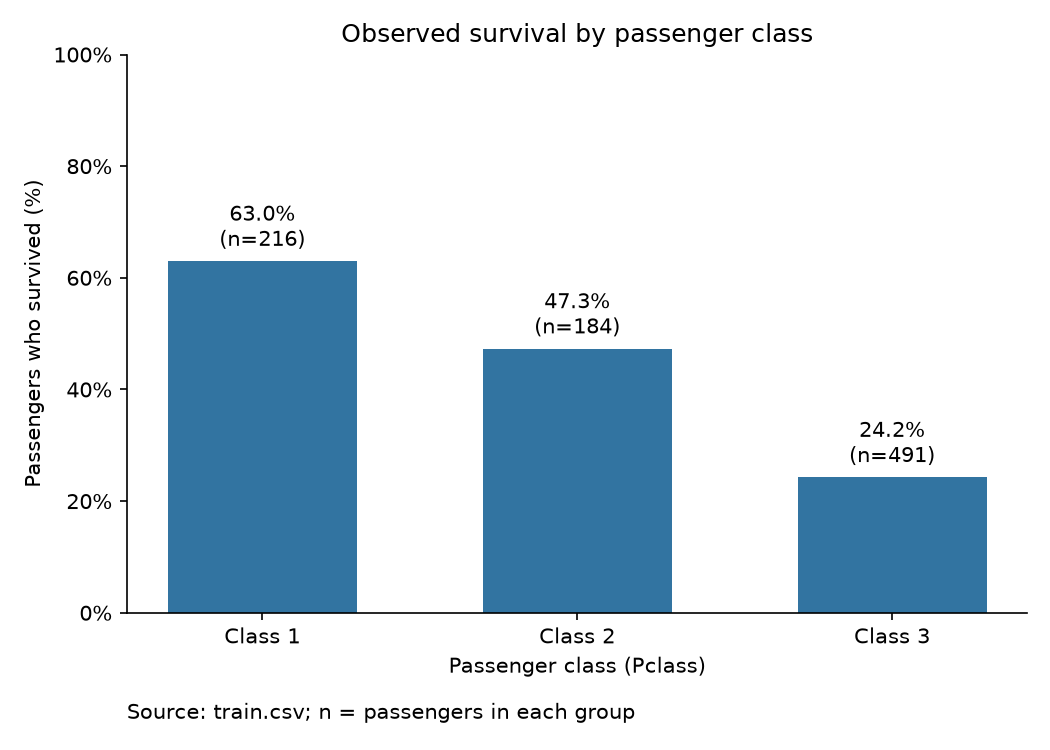

In [9]:
display(Image(data=(out / "survival_by_pclass.png").read_bytes()))

## Plot 2: survival by recorded sex

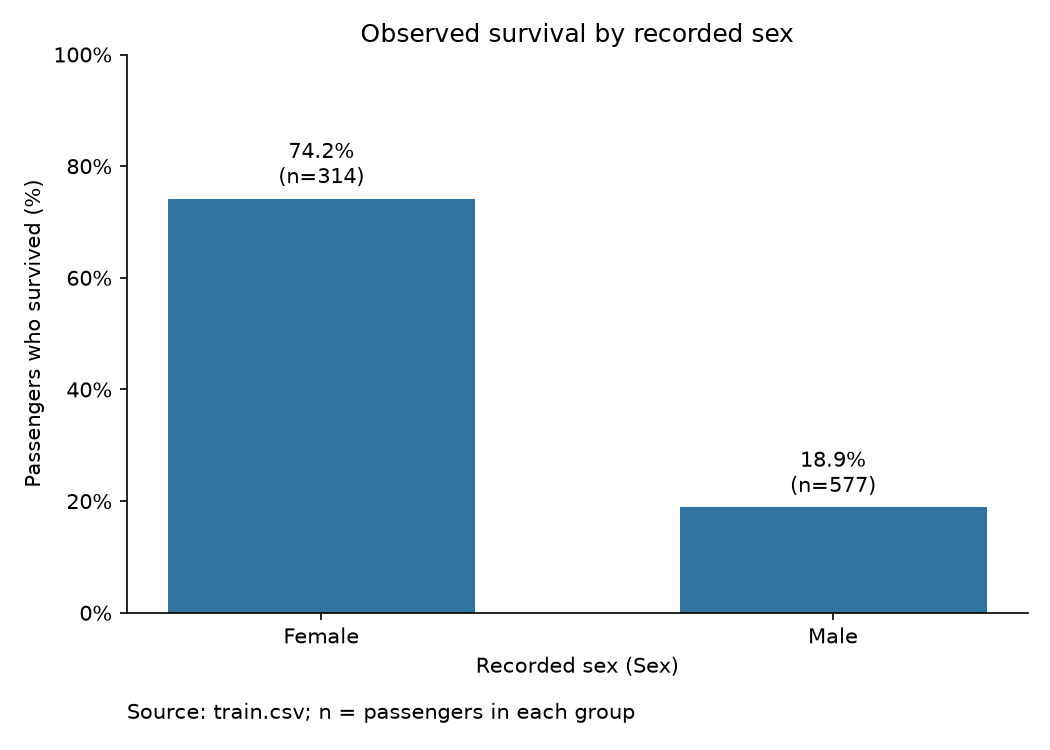

In [10]:
display(Image(data=(out / "survival_by_sex.png").read_bytes()))

## Observed associations and limitations

In [11]:
display(Markdown((out / "summary.md").read_text()))

# Titanic: introductory descriptive analysis

The analysis uses 891 training passengers with observed survival outcomes.
Overall, 342 survived (38.4%).
The 418 test passengers have no observed survival outcomes; the sample submission
is an example output, not ground truth. Neither supplies outcomes for this analysis.

## Missing values

- train.csv, Age: 177 missing (19.9%).
- train.csv, Cabin: 687 missing (77.1%).
- train.csv, Embarked: 2 missing (0.2%).
- test.csv, Age: 86 missing (20.6%).
- test.csv, Fare: 1 missing (0.2%).
- test.csv, Cabin: 327 missing (78.2%).

All other columns have zero missing values. Survived, Pclass, and Sex are complete
in the training data, so all training passengers contribute to these survival rates.
No missing values were filled, and no rows were dropped.

## Survival rates

Each rate is survivors divided by passengers in that group, multiplied by 100.
For a binary 0/1 outcome this is also the group's mean of Survived, multiplied by 100.

| Pclass | Passengers | Survivors | Survival rate |
| --- | --- | --- | --- |
| 1 | 216 | 136 | 63.0% |
| 2 | 184 | 87 | 47.3% |
| 3 | 491 | 119 | 24.2% |

| Sex | Passengers | Survivors | Survival rate |
| --- | --- | --- | --- |
| female | 314 | 233 | 74.2% |
| male | 577 | 109 | 18.9% |

The joint groups help inspect how the two recorded characteristics overlap:

| Pclass | Sex | Passengers | Survivors | Survival rate |
| --- | --- | --- | --- | --- |
| 1 | female | 94 | 91 | 96.8% |
| 1 | male | 122 | 45 | 36.9% |
| 2 | female | 76 | 70 | 92.1% |
| 2 | male | 108 | 17 | 15.7% |
| 3 | female | 144 | 72 | 50.0% |
| 3 | male | 347 | 47 | 13.5% |

## Observed associations and limitations

In this sample, survival was higher in first class (63.0%) than second
(47.3%) or third (24.2%). Passengers recorded as female had a
higher survival rate (74.2%) than those recorded as male (18.9%).
These are descriptive associations, not evidence that class or sex caused survival.
The separate group rates do not adjust for age, family circumstances, or other factors;
the joint table is still descriptive. Group sizes differ, and this workshop training
sample may not represent all Titanic passengers or other populations. Missing age
and cabin data limit broader comparisons. No uncertainty intervals or significance
tests were calculated, and the dataset's binary Sex labels limit the categories described.
No predictive model was trained by this analysis.

The two charts label axes, percentages, and group passenger counts; they show observed
proportions rather than predictions.
